# 1. Pozyskanie i eksploracja danych (Financial PhraseBank)

W projekcie wykorzystujemy zbiór **Financial PhraseBank** (`takala/financial_phrasebank`), który zawiera krótkie zdania z wiadomości finansowych w języku angielskim ocenione przez 5–8 anotatorów pod kątem wydźwięku: `positive`, `neutral`, `negative`.

In [1]:
import io
import urllib.request
import zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Wariant zbioru: Sentences_75Agree.txt (min. 75% zgodności)
VARIANT_FILE = "Sentences_75Agree.txt"
DATA_URL = "https://huggingface.co/datasets/takala/financial_phrasebank/resolve/main/data/FinancialPhraseBank-v1.0.zip"

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

raw_csv_path = RAW_DIR / "financial_phrasebank.csv"

if not raw_csv_path.exists():
    response = urllib.request.urlopen(DATA_URL)
    zip_bytes = io.BytesIO(response.read())
    rows = []
    with zipfile.ZipFile(zip_bytes) as z:
        with z.open(f"FinancialPhraseBank-v1.0/{VARIANT_FILE}") as f:
            for line in f:
                decoded = line.decode("iso-8859-1").strip()
                if "@" in decoded:
                    sentence, label = decoded.rsplit("@", 1)
                    rows.append({"sentence": sentence.strip(), "label": label.strip()})
    df = pd.DataFrame(rows)
    df.to_csv(raw_csv_path, index=False, encoding="utf-8")
else:
    df = pd.read_csv(raw_csv_path)

print(f"Liczba wierszy przed czyszczeniem: {len(df)}")
df = df.drop_duplicates(subset=["sentence"]).reset_index(drop=True)
print(f"Liczba unikalnych zdań po usunięciu duplikatów: {len(df)}")

df.head(10)

Liczba wierszy przed czyszczeniem: 3453
Liczba unikalnych zdań po usunięciu duplikatów: 3448


,sentence,label
0,"According to Gran , the company has no plans t...",neutral
1,With the new production plant the company woul...,positive
2,"For the last quarter of 2010 , Componenta 's n...",positive
3,"In the third quarter of 2010 , net sales incre...",positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive
5,"Operating profit totalled EUR 21.1 mn , up fro...",positive
6,TeliaSonera TLSN said the offer is in line wit...,positive
7,"STORA ENSO , NORSKE SKOG , M-REAL , UPM-KYMMEN...",positive
8,"A purchase agreement for 7,200 tons of gasolin...",positive
9,Finnish Talentum reports its operating profit ...,positive


,Liczba zdań,Udział (%)
label,,
neutral,2141,62.09
positive,887,25.73
negative,420,12.18


Średnia długość zdania: 22.8 słów (min: 2, max: 81)


C:\Users\samol\AppData\Local\Temp\ipykernel_16180\24175599.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", order=["neutral", "positive", "negative"], palette=["#7f8c8d", "#27ae60", "#c0392b"])


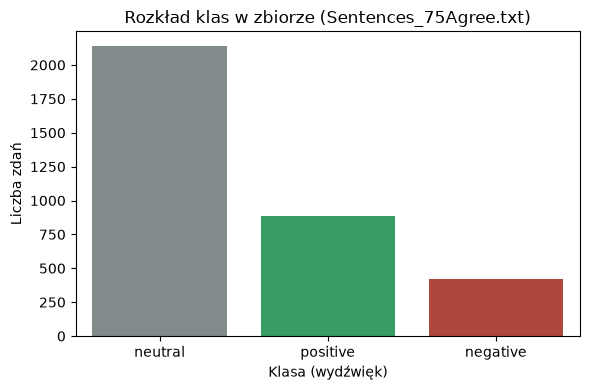

In [ ]:
# Rozkład klas
counts = df["label"].value_counts()
percents = (df["label"].value_counts(normalize=True) * 100).round(2)
summary_df = pd.DataFrame({"Liczba zdań": counts, "Udział (%)": percents})
display(summary_df)

# Długość zdań w słowach
df["word_count"] = df["sentence"].apply(lambda x: len(str(x).split()))
print(f"Średnia długość zdania: {df['word_count'].mean():.1f} słów (min: {df['word_count'].min()}, max: {df['word_count'].max()})")

# Wykres rozkładu klas
plt.figure(figsize=(6, 4))
sns.countplot(
    data=df,
    x="label",
    hue="label",
    order=["neutral", "positive", "negative"],
    palette=["#7f8c8d", "#27ae60", "#c0392b"],
    legend=False,
)
plt.title(f"Rozkład klas w zbiorze ({VARIANT_FILE})")
plt.xlabel("Klasa (wydźwięk)")
plt.ylabel("Liczba zdań")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "class_distribution.png", dpi=150)
plt.show()

In [3]:
train_df, test_df = train_test_split(
    df[["sentence", "label"]],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

train_df.to_csv(PROCESSED_DIR / "train.csv", index=False, encoding="utf-8")
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False, encoding="utf-8")

print(f"Zbiór uczący (80%): {len(train_df)} zdań -> zapisano w data/processed/train.csv")
print(f"Zbiór testowy (20%): {len(test_df)} zdań -> zapisano w data/processed/test.csv")

Zbiór uczący (80%): 2758 zdań -> zapisano w data/processed/train.csv
Zbiór testowy (20%): 690 zdań -> zapisano w data/processed/test.csv
